# EEG seizure detection — complete mini-project
A simple pipeline covering all requirements through section 19 of the assignment.
Questions 1–14 are followed by sections 15, 16, 18 and 19; the PDF skips number 17.
We use one recording and one EEG channel to keep the calculations easy to follow.
The signal is supplied as MATLAB files; seizure annotations are in Excel.

**Source convention requested by the user:** seizure starts come from explicit `ABSENCE`
markers in the header; durations come from Excel (`FinCE − DebCE`, in HH:MM:SS).
We use `210928B_B_0000`: it has two explicit markers and two Excel seizure intervals.
Pair them chronologically and compute `end = header start + Excel duration`.
This chronological pairing is an assumption; the files have no shared seizure identifiers.
The previous recording had no explicit seizure markers and is not used for this analysis.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data import load_recording, load_seizure_annotations, summarize
from src.labeling import select_seizures, seizure_statistics, label_samples, seizures_from_header
from src.windowing import make_windows
from src.features import extract_features, fft_power, BANDS
from src.training import train_models, purge_overlaps
from src.evaluation import evaluate_models
from src.detection import detected_intervals, compare_intervals
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

RECORDING_ID = '210928B_B_0000'
CHANNEL = 'EEGFp1'
WINDOW_SECONDS = 2.0
OVERLAP = 0.5
TABLES = ROOT / 'reports/tables'
FIGURES = ROOT / 'reports/figures'
RESULTS = ROOT / 'outputs/results'
for folder in (TABLES, FIGURES, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=130, bbox_inches='tight')
    plt.show()

## Q1–Q2 — Load, inspect and visualize
The loader reconstructs the original MATLAB timetable. No rows are removed.
Amplitude units are not recorded in the source, so plots use “source units”.

,Propriete,Valeur
0,Fichier de signal,210928B_B_0000d.mat
1,Fichier d'entete,210928B_B_0000h.mat
2,Nombre de lignes (echantillons),344 064
3,Nombre de variables (colonnes),22
4,dont canaux de mesure,21
5,dont canaux EEG,19
6,Canaux non EEG,"SLI, ECG"
7,Frequence d'echantillonnage,256.0 Hz
8,Periode d'echantillonnage,3.906 ms
9,Duree totale,1344.0 s (22 min 24.0 s)


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,...,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.000000,54.322957,43.225681,-813.591440,-573.389105,67.926070,-1109.638132,-611.155642,151.871595,-4.027237,...,-502.509728,-811.085603,-936.556420,60.229572,-860.844358,-950.338521,-1116.618677,-737.700389,0.089494,-431.272374
1,0.003906,53.070039,36.245136,-823.256809,-576.252918,58.439689,-1121.988327,-621.715953,137.731518,-12.439689,...,-509.132296,-821.466926,-946.221790,50.027237,-872.657588,-958.571984,-1125.926070,-744.501946,0.089494,-234.385214
2,0.007812,7.785992,-12.439689,-873.373541,-621.536965,12.439689,-1170.673152,-672.548638,86.719844,-57.007782,...,-554.953307,-868.540856,-997.770428,2.416342,-922.237354,-1005.645914,-1174.789883,-793.186770,0.089494,-157.420233
3,0.011719,-19.957198,-45.015564,-895.031128,-649.638132,-12.260700,-1195.194553,-694.922179,63.451362,-80.813230,...,-579.116732,-892.883268,-1027.482490,-26.400778,-948.369650,-1030.704280,-1203.964981,-825.762646,0.089494,-86.361868
4,0.015625,7.428016,-18.883268,-863.708171,-623.326848,16.914397,-1161.902724,-667.000000,97.101167,-51.638132,...,-552.805447,-866.929961,-999.739300,-2.416342,-918.836576,-1002.603113,-1173.536965,-802.315175,0.089494,-37.856031


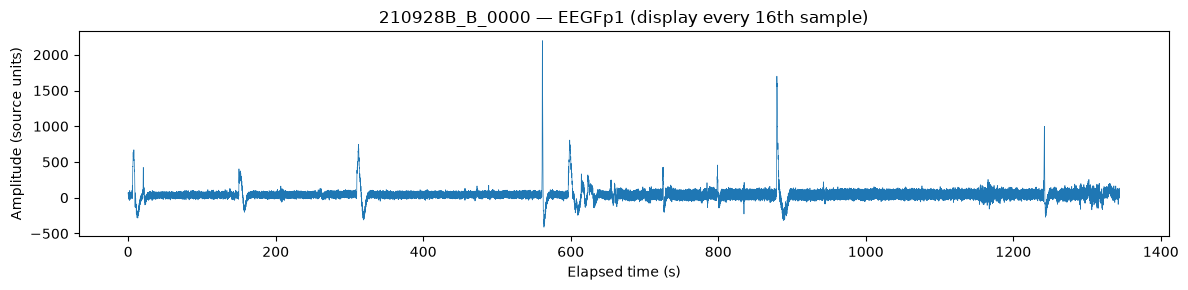

In [2]:
recording = load_recording(RECORDING_ID, ROOT)
fs = recording.sampling_rate
signal = recording.channel(CHANNEL)
display(summarize(recording))
display(recording.data.head())
assert np.isfinite(signal).all(), 'Inspect missing or infinite signal values before proceeding.'
plt.figure(figsize=(12, 3))
plt.plot(recording.time[::16], signal[::16], linewidth=0.5)
plt.xlabel('Elapsed time (s)')
plt.ylabel('Amplitude (source units)')
plt.title(f'{RECORDING_ID} — {CHANNEL} (display every 16th sample)')
save_figure('q2_signal')

## Q3–Q4 — Annotations and seizure durations
Excel stores clock times as fractions of one day: multiply by 86,400.
Here, durations and gaps are calculated from Excel clock times. Header-based gaps are calculated next. “Gap” means the end of one
seizure to the start of the next, not the difference between their start times.

In [3]:
annotations = load_seizure_annotations(ROOT, time_unit='excel_days')
clock_seizures = select_seizures(annotations, RECORDING_ID)
clock_table = clock_seizures[['seizure', 'start_s', 'end_s', 'duration_s']].copy()
for col in ['start_s', 'end_s']:
    clock_table[col] = pd.to_timedelta(clock_table[col], unit='s').astype(str)
display(clock_table.rename(columns={'start_s': 'start_clock', 'end_s': 'end_clock'}))
statistics = seizure_statistics(clock_seizures)
display(statistics.round(3))
clock_table.rename(columns={'start_s': 'start_clock', 'end_s': 'end_clock'}).to_csv(TABLES / 'q3_clock_seizures.csv', index=False)
statistics.to_csv(TABLES / 'q4_clock_statistics.csv', index=False)
print('Longest / shortest duration:', round(statistics.max_duration_s.iloc[0] / statistics.min_duration_s.iloc[0], 2))

,seizure,start_clock,end_clock,duration_s
0,1,0 days 09:27:07,0 days 09:27:37,30.0
1,2,0 days 09:29:25,0 days 09:29:50,25.0


,seizure_count,mean_duration_s,min_duration_s,max_duration_s,mean_gap_s,mean_onset_interval_s
0,2,27.5,25.0,30.0,108.0,138.0


Longest / shortest duration: 1.2


## Q5–Q6 — Header starts, sample labels and class imbalance
A sample is in class 1 when its timestamp belongs to a closed interval `[start, end]`.
Use header onset times directly and add the corresponding Excel duration. Require equal
numbers of explicit markers and Excel intervals. The clock intervals and header intervals
have different inter-seizure gaps; report this discrepancy rather than treating the
markers as an exact clock conversion.

,seizure,header_label,start_s,end_s,duration_s
0,1,ABSENCE,1162.164062,1192.164062,30.0
1,2,ABSENCE,1291.914062,1316.914062,25.0


,seizure_count,mean_duration_s,min_duration_s,max_duration_s,mean_gap_s,mean_onset_interval_s
0,2,27.5,25.0,30.0,99.75,129.75


,Samples,Percent
Class,,
0,329982,95.907157
1,14082,4.092843


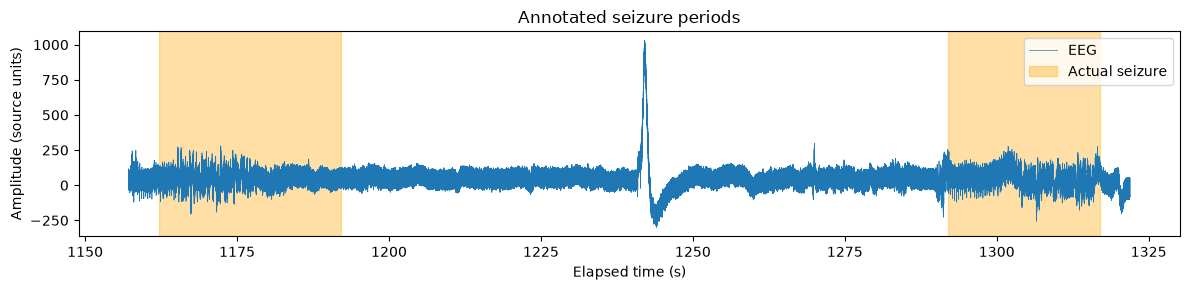

Excel onset spacings (s): [138.]
Header onset spacings (s): [129.75]


In [4]:
seizures = seizures_from_header(recording.events, clock_seizures)
statistics = seizure_statistics(seizures)
statistics.to_csv(TABLES / 'q4_statistics.csv', index=False)
display(seizures[['seizure', 'header_label', 'start_s', 'end_s', 'duration_s']])
display(statistics.round(3))
labeled = label_samples(recording, seizures)
seizures.to_csv(TABLES / 'q3_seizures.csv', index=False)
class_balance = labeled.Class.value_counts().reindex([0, 1], fill_value=0).rename('Samples').to_frame()
class_balance['Percent'] = 100 * class_balance.Samples / len(labeled)
display(class_balance)
class_balance.to_csv(TABLES / 'q6_class_balance.csv')
# The source signal stays intact; save the target separately to avoid duplicating all channels.
labeled[['Time', 'Class']].to_csv(RESULTS / 'sample_labels.csv.gz', index=False)
start, end = seizures.start_s.min() - 5, seizures.end_s.max() + 5
visible = (recording.time >= start) & (recording.time <= end)
plt.figure(figsize=(12, 3))
plt.plot(recording.time[visible], signal[visible], lw=0.5, label='EEG')
for i, row in enumerate(seizures.itertuples()):
    plt.axvspan(row.start_s, row.end_s, color='orange', alpha=0.35, label='Actual seizure' if i == 0 else None)
plt.xlabel('Elapsed time (s)'); plt.ylabel('Amplitude (source units)')
plt.title('Annotated seizure periods'); plt.legend()
save_figure('q6_labels')
print('Excel onset spacings (s):', np.diff(clock_seizures.start_s))
print('Header onset spacings (s):', np.diff(seizures.start_s))

### Visual interpretation
For `210928B_B_0000`, both labeled intervals show periods of larger oscillations than
much of the surrounding signal. However, a much larger isolated transient occurs
outside the labeled intervals, near 1242 s. Amplitude alone cannot distinguish
seizures from other activity or artifacts. Class 1 contains about 4.09% of samples,
so the dataset is strongly imbalanced.

## Q7–Q9 — Windows, temporal features and FFT
Use 2-second windows with 50% overlap. A window is class 1 if at least half of its samples
are class 1. Discard any incomplete final window. Features use the raw signal; finite-value
checks are the only preprocessing before windowing. Normalization is fitted inside the
KNN/SVM training pipelines.

Temporal features: mean, standard deviation, variance, minimum, maximum, peak-to-peak
amplitude, RMS and energy. FFT power uses mean-centered windows and a one-sided
periodogram. Band power is the sum of spectral density × frequency-bin width.
Bands are half-open: Delta [0.5,4), Theta [4,8), Alpha [8,13), Beta [13,30) Hz.

,start_s,end_s,seizure_fraction,Class,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Delta,Theta,Alpha,Beta
0,0.0,2.0,0.0,0,23.776082,32.216881,1037.927444,-41.793774,107.303502,149.097276,40.040349,8.208535e+05,121.788580,6.840013,4.210855,3.058673
1,1.0,3.0,0.0,0,25.918698,34.561982,1194.530598,-41.793774,107.303502,149.097276,43.200805,9.555505e+05,266.735048,9.348648,2.366686,3.080808
2,2.0,4.0,0.0,0,30.432211,38.784857,1504.265142,-82.961089,116.431907,199.392996,49.298931,1.244357e+06,459.483610,119.091029,12.234404,4.137557
3,3.0,5.0,0.0,0,33.549474,39.035712,1523.786792,-82.961089,116.431907,199.392996,51.471876,1.356469e+06,503.397917,108.781625,12.456762,3.643835
4,4.0,6.0,0.0,0,73.501626,86.867023,7545.879733,-40.003891,408.540856,448.544747,113.790899,6.629565e+06,5782.958006,418.503248,188.230468,167.544541


Total windows: 1343 
Windows by class:
 Class
0    1288
1      55
Name: count, dtype: int64
FFT resolution: 0.5 Hz


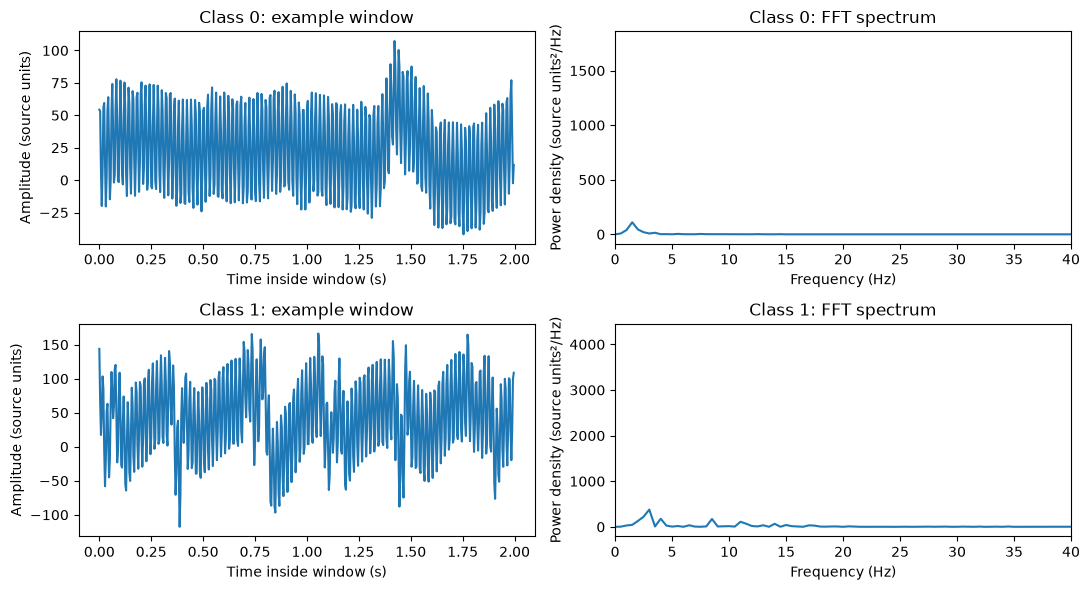

In [5]:
windows, metadata = make_windows(signal, labeled.Class, fs, WINDOW_SECONDS, OVERLAP, recording.time[0])
features = extract_features(windows, fs)
dataset = pd.concat([metadata, features], axis=1)
dataset.to_csv(RESULTS / 'window_features.csv', index=False)
display(dataset.head())
window_counts = dataset.Class.value_counts().reindex([0, 1], fill_value=0)
print('Total windows:', len(dataset), '\nWindows by class:\n', window_counts)
print('FFT resolution:', fs / windows.shape[1], 'Hz')
assert dataset.Class.nunique() == 2, 'Both classes are required for classification.'
frequencies, power = fft_power(windows, fs)
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for cls in [0, 1]:
    i = dataset.index[dataset.Class == cls][0]
    axes[cls, 0].plot(np.arange(windows.shape[1]) / fs, windows[i])
    axes[cls, 0].set(xlabel='Time inside window (s)', ylabel='Amplitude (source units)', title=f'Class {cls}: example window')
    axes[cls, 1].plot(frequencies, power[i])
    axes[cls, 1].set(xlim=(0, 40), xlabel='Frequency (Hz)', ylabel='Power density (source units²/Hz)', title=f'Class {cls}: FFT spectrum')
save_figure('q9_fft')

## Q10–Q11 — Compare features and correlations
Class means describe differences; they do not prove that a feature generalizes to new data.
The correlation matrix excludes labels and timestamps. Constant-feature correlations are undefined.
Energy and RMS, and variance and standard deviation, contain mathematically related information.

,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,Delta,Theta,Alpha,Beta
Class,,,,,,,,,,,,
0,45.312,49.370,4275.306,-46.344,143.356,189.700,77.383,6518122.154,2396.827,65.240,21.020,18.247
1,48.635,64.931,4327.010,-115.807,203.092,318.899,82.977,3644217.320,1373.938,189.699,154.484,92.502


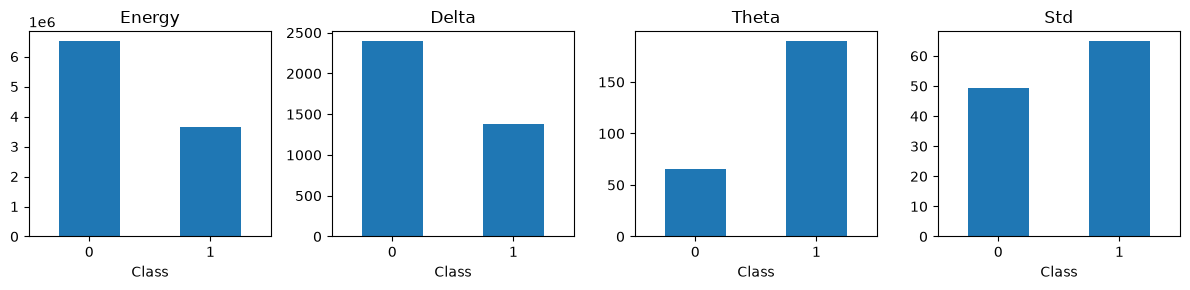

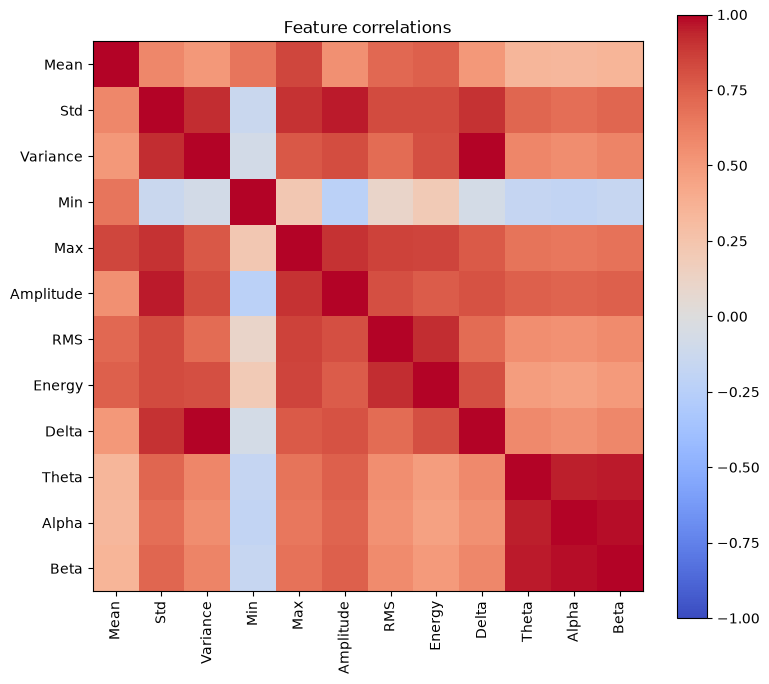

Correlation
Variance Delta         0.999457
Alpha    Beta          0.983161
Theta    Beta          0.960093
Std      Amplitude     0.957933
Theta    Alpha         0.951134
RMS      Energy        0.917697
Std      Variance      0.914879
         Delta         0.905366

,Absolute standardized mean difference
Min,1.169630
Amplitude,1.093194
Alpha,1.048938
Beta,0.753897
Max,0.550764
Std,0.498063
Theta,0.480113
Energy,0.108723
RMS,0.094662
Mean,0.056808


In [6]:
class_means = dataset.groupby('Class')[features.columns].mean()
display(class_means.round(3))
class_means.to_csv(TABLES / 'q10_class_means.csv')
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, name in zip(axes, ['Energy', 'Delta', 'Theta', 'Std']):
    class_means[name].plot.bar(ax=ax, rot=0, title=name)
    ax.set_xlabel('Class')
save_figure('q10_features')
correlation = features.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(features.columns)), features.columns, rotation=90)
ax.set_yticks(range(len(features.columns)), features.columns)
fig.colorbar(im, ax=ax)
ax.set_title('Feature correlations')
save_figure('q11_correlation')
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
strong_pairs = pairs[pairs.abs() >= 0.9].sort_values(key=abs, ascending=False)
display(strong_pairs.rename('Correlation').to_frame())
# Descriptive ranking only; no feature selection is performed using test data.
pooled_std = np.sqrt((dataset.groupby('Class')[features.columns].var().sum()) / 2)
effect = ((class_means.loc[1] - class_means.loc[0]).abs() / pooled_std.replace(0, np.nan)).sort_values(ascending=False)
display(effect.rename('Absolute standardized mean difference').to_frame())

## Q12 — Split and train four models
First make the requested stratified 80/20 split (fixed seed). With overlapping windows,
neighboring train/test windows can share raw samples. Remove training windows that overlap
any test window. The initial split is 80/20; the retained training set is smaller after this purge.
The test set stays untouched. Class proportions are displayed before and after purging.

Select the model by mean F1 from three training-only validation folds. Validation also purges
overlapping windows. This prevents shared-sample leakage, but windows from the same recording
are still correlated: these results do not measure generalization to new patients.

In [7]:
train_index, test_index = train_test_split(dataset.index.to_numpy(), test_size=0.2,
                                         stratify=dataset.Class, random_state=42)
initial_train_index = train_index.copy()
train_index = purge_overlaps(metadata, train_index, test_index)
X_train, X_test = features.loc[train_index], features.loc[test_index]
y_train, y_test = dataset.Class.loc[train_index], dataset.Class.loc[test_index]
display(pd.DataFrame({'Initial train': dataset.Class.loc[initial_train_index].value_counts(),
                      'Retained train': y_train.value_counts(), 'Test': y_test.value_counts()}).fillna(0).astype(int))
models, cv_scores, best_name = train_models(X_train, y_train, metadata.loc[train_index])
display(cv_scores.round(4))
print('Model selected using training validation:', best_name)
cv_scores.to_csv(TABLES / 'q12_validation.csv')

,Initial train,Retained train,Test
Class,,,
0,1030,670,258
1,44,24,11


,CV F1
Model,
Decision Tree,0.4843
Random Forest,0.5710
KNN,0.5954
SVM,0.4583


Model selected using training validation: KNN


## Evaluation and Q13 — Which metric matters?
Recall measures how many positive windows are detected. Precision measures how many alerts
are correct. F1 balances the two. Accuracy alone is misleading with rare seizures: always
predicting class 0 can give a high score. All precision/recall/F1 values below concern class 1;
a metric with no predicted positives is reported as zero.

The baseline always predicts class 0. Confusion matrix rows are actual classes and columns
are predictions: `[[TN, FP], [FN, TP]]`.

,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.9554,0.4444,0.3636,0.4000
Random Forest,0.9665,0.5714,0.7273,0.6400
KNN,0.9740,0.7500,0.5455,0.6316
SVM,0.9442,0.4091,0.8182,0.5455


Always-negative baseline accuracy: 0.9591078066914498
Baseline precision, recall and F1: 0


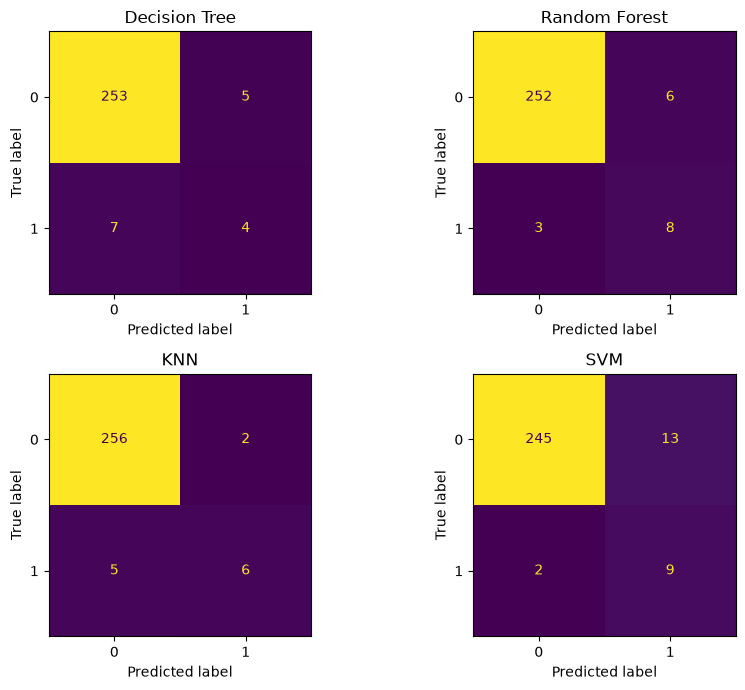

In [8]:
scores, predictions, matrices = evaluate_models(models, X_test, y_test)
display(scores.round(4))
print('Always-negative baseline accuracy:', (y_test == 0).mean())
print('Baseline precision, recall and F1: 0')
scores.to_csv(TABLES / 'q13_model_comparison.csv')
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (name, matrix) in zip(axes.flat, matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
save_figure('q13_confusion_matrices')

## Q14 — Temporal detection and comparison
Reconstruct intervals from positive **test** windows only. Merge touching/overlapping positive
windows, but never bridge a gap with no test prediction. Test coverage is shown separately;
uncovered time is unknown, not a negative prediction. Compare each detected interval with the
annotation giving its largest temporal intersection-over-union (IoU).
This scattered test set cannot reconstruct complete seizure episodes reliably.

,start_s,end_s,duration_s
0,1160.0,1162.0,2.0
1,1163.0,1165.0,2.0
2,1168.0,1170.0,2.0
3,1171.0,1173.0,2.0
4,1290.0,1292.0,2.0
5,1303.0,1308.0,5.0


,predicted_start_s,predicted_end_s,actual_start_s,actual_end_s,IoU
0,1160.0,1162.0,NaN,NaN,0.000000
1,1163.0,1165.0,1162.164062,1192.164062,0.066667
2,1168.0,1170.0,1162.164062,1192.164062,0.066667
3,1171.0,1173.0,1162.164062,1192.164062,0.066667
4,1290.0,1292.0,1291.914062,1316.914062,0.003193
5,1303.0,1308.0,1291.914062,1316.914062,0.200000


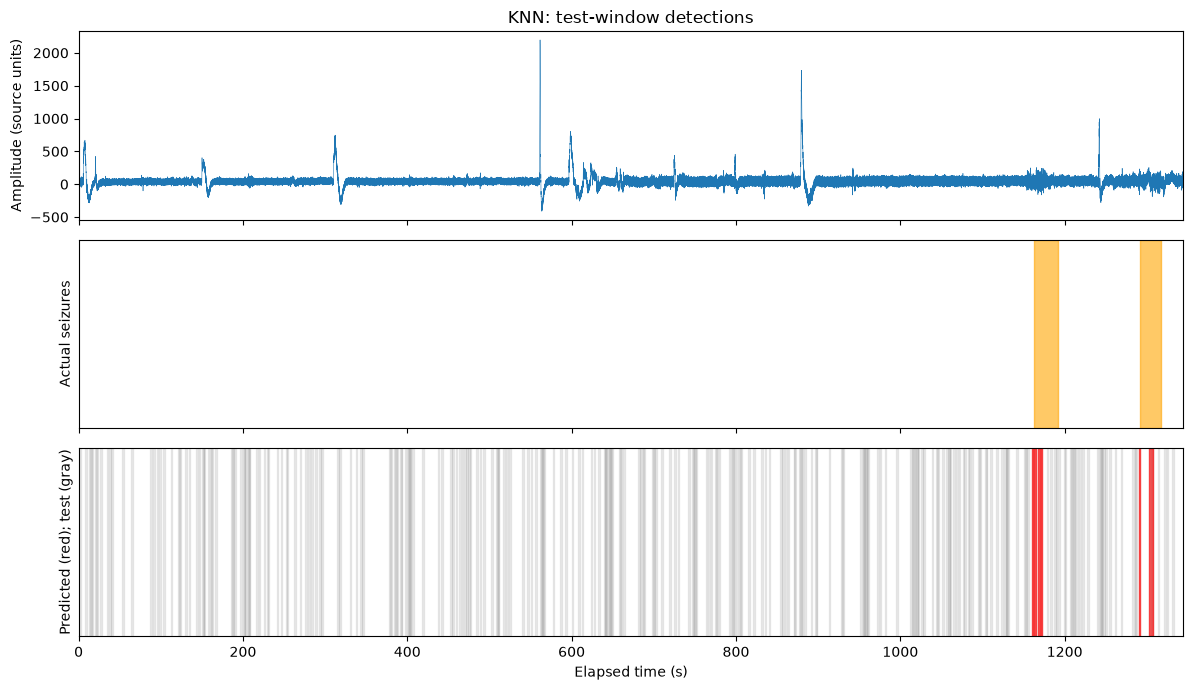

In [9]:
test_windows = metadata.loc[test_index].copy()
best_predictions = predictions[best_name]
detected = detected_intervals(test_windows, best_predictions)
comparison = compare_intervals(detected, seizures)
display(detected)
display(comparison)
detected.to_csv(TABLES / 'q14_detected_intervals.csv', index=False)
comparison.to_csv(TABLES / 'q14_interval_comparison.csv', index=False)
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(recording.time[::8], signal[::8], lw=0.4)
axes[0].set_ylabel('Amplitude (source units)')
for row in seizures.itertuples():
    axes[1].axvspan(row.start_s, row.end_s, color='orange', alpha=0.6)
for row in test_windows.itertuples():
    axes[2].axvspan(row.start_s, row.end_s, color='gray', alpha=0.15)
for row in detected.itertuples():
    axes[2].axvspan(row.start_s, row.end_s, color='red', alpha=0.6)
axes[1].set_ylabel('Actual seizures')
axes[2].set_ylabel('Predicted (red); test (gray)')
axes[2].set_xlabel('Elapsed time (s)')
axes[0].set_title(f'{best_name}: test-window detections')
for ax in axes[1:]:
    ax.set_yticks([])
axes[2].set_xlim(0, recording.duration)
save_figure('q14_detection')

## 15 — Error analysis
List every test window as TP, TN, FP or FN. False negatives are missed positive windows;
false positives are unnecessary alerts. Inspect their timestamps against the actual EEG.
Possible causes include artifacts, window boundaries and features shared by both classes;
the counts alone do not establish a cause.

In [10]:
errors = test_windows.copy()
errors['Prediction'] = best_predictions
errors['Outcome'] = np.select(
    [(errors.Class == 1) & (errors.Prediction == 1),
     (errors.Class == 0) & (errors.Prediction == 1),
     (errors.Class == 1) & (errors.Prediction == 0)],
    ['TP', 'FP', 'FN'], default='TN')
errors = errors.sort_values('start_s')
error_counts = errors.Outcome.value_counts().reindex(['TN', 'FP', 'FN', 'TP'], fill_value=0)
display(error_counts.rename('Windows').to_frame())
display(errors[errors.Outcome.isin(['FP', 'FN'])].head(20))
errors.to_csv(RESULTS / 'test_predictions.csv', index=False)

,Windows
Outcome,
TN,256
FP,2
FN,5
TP,6


,start_s,end_s,seizure_fraction,Class,Prediction,Outcome
1160,1160.0,1162.0,0.000000,0,1,FP
1178,1178.0,1180.0,1.000000,1,0,FN
1182,1182.0,1184.0,1.000000,1,0,FN
1187,1187.0,1189.0,1.000000,1,0,FN
1189,1189.0,1191.0,1.000000,1,0,FN
1290,1290.0,1292.0,0.042969,0,1,FP
1313,1313.0,1315.0,1.000000,1,0,FN


## 16 — Improvements and limitations
1. Validate on separate recordings/patients and verify correspondence between header markers and Excel intervals before interpreting performance.
2. Compare window durations and overlap using training-only validation; this changes detection delay and boundary errors.
3. Compare artifact removal and additional EEG channels, and tune class weights or decision thresholds on validation data.

Scaling is already included for KNN/SVM; balanced class weights are used for the tree models and SVM.
We propose these experiments without claiming unmeasured improvements. A single recording,
correlated windows and scattered test coverage limit the conclusions. This is a classroom model,
not a validated seizure detector.

## 18 — Deliverables: notebook and report
This cell writes a short report from the actual results above. It runs only after the full analysis succeeds.

In [11]:
def markdown_table(frame):
    table = frame.reset_index() if frame.index.name or not isinstance(frame.index, pd.RangeIndex) else frame
    return '| ' + ' | '.join(map(str, table.columns)) + ' |\n' + '| ' + ' | '.join(['---'] * len(table.columns)) + ' |\n' + '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in table.itertuples(index=False, name=None))

report = f"""# EEG seizure detection — project report

## Introduction
Detect annotated seizure periods from EEG using a simple classification pipeline.
Recording: `{RECORDING_ID}`. Channel: `{CHANNEL}`. The scope is one recording.

## Data and annotations
There are {recording.n_samples:,} samples, {recording.n_variables} original variables,
{fs:g} Hz sampling, {recording.duration:g} s duration and {recording.n_missing()} missing values.
Amplitude units are not supplied. Excel annotation times are HH:MM:SS;
only their differences are used as durations. Following the requested convention,
explicit header seizure markers supply elapsed starts. The {len(seizures)} markers
are paired chronologically with the {len(clock_seizures)} Excel intervals.
This pairing is assumed from order and count, not verified by shared event identifiers.
Excel onset spacing is 138 s; header onset spacing is 129.75 s (difference 8.25 s); header markers may have annotation delay.
These are operational labels for this exercise, not precisely validated clinical boundaries.

{markdown_table(seizures[['seizure', 'start_s', 'end_s', 'duration_s']].round(4))}
There are {len(seizures)} seizures. Durations range from {statistics.min_duration_s.iloc[0]:.3f}
to {statistics.max_duration_s.iloc[0]:.3f} s, with a mean of {statistics.mean_duration_s.iloc[0]:.3f} s.
The mean gap from one seizure end to the next start is {statistics.mean_gap_s.iloc[0]:.3f} s.
Durations therefore vary; see the full annotation table in the notebook.

{markdown_table(class_balance.round(3))}

## Methodology
Closed annotation intervals label original samples. Complete {WINDOW_SECONDS:g}-second windows,
{OVERLAP:.0%} overlap, and the 50% positive-sample rule produce {len(dataset)} windows,
including {window_counts.loc[1]} positive windows. Eight temporal features and four FFT band
powers are extracted from raw EEG. FFT resolution is {fs/windows.shape[1]:g} Hz.
A stratified 80/20 split is followed by removal of overlapping training windows:
{len(initial_train_index)} initial train, {len(train_index)} retained train and {len(test_index)} test windows.
KNN/SVM scaling is fitted inside training folds. Training-only, overlap-purged 3-fold F1 selects
**{best_name}**; the test set is not used for selection.

## Exploration
In the labeled signal plot, oscillations are larger during parts of both labeled
intervals, but the largest isolated transient (near 1242 s) occurs outside them.
Amplitude alone is therefore insufficient. Only 4.09% of samples are positive.

The largest descriptive standardized class differences are: {', '.join(effect.head(3).index)}.
There are {len(strong_pairs)} feature pairs with absolute correlation >= 0.9.
Standard deviation/variance and RMS/energy are mathematically redundant transformations.
Class means and correlation plots are available in the notebook; descriptive differences
are not evidence of performance on new patients.

## Results
{markdown_table(scores.round(4))}

Always-negative baseline accuracy: {(y_test == 0).mean():.4f}; baseline positive recall/F1: 0.
Recall matters for missed seizures; precision measures false alerts. F1 balances both.
Accuracy alone can conceal the class imbalance.

## 14–15 — Temporal detection and errors
The selected model produces {len(detected)} merged positive test intervals.
See `tables/q14_detected_intervals.csv` and `tables/q14_interval_comparison.csv` for boundaries
and comparisons with actual annotations. Untested gaps remain unknown; detections from this
scattered test set are fragments, not complete reconstructed seizures.

{markdown_table(error_counts.rename('Windows').to_frame())}

False positives are unnecessary alerts; false negatives are missed positive windows.
Artifacts and boundary effects are possible causes, not established diagnoses.
Every test-window prediction and its outcome are saved in `../outputs/results/test_predictions.csv`.

## 16 — Conclusion and improvements
The complete pipeline runs from raw MATLAB EEG and Excel annotations to features,
four classifiers, evaluation, temporal detections and error analysis.
The results describe this recording only. Shared-patient correlation remains despite
purging shared samples. Validate on independent recordings, compare window durations,
and test artifact removal, additional channels or class-weight/threshold tuning using
training-only validation. These improvements are proposed, not claimed as measured gains.

## 18 — Deliverables
The executed notebook is `../notebooks/main.ipynb`; this file is the report.
The notebook contains every requested step, including plots and numerical results.
The PDF skips section 17.

## 19 — Complete pipeline
Raw EEG + Excel annotations → exploration and finite-value checks → sample labels
→ 2-second windows → eight temporal features + four FFT band powers
→ classification dataset → stratified split and overlap removal
→ Decision Tree / Random Forest / KNN / SVM → evaluation
→ model selected by training-validation F1 → predicted seizure starts and ends.

Preprocessing is deliberately minimal: inspect missing/nonfinite values, choose one
EEG channel, and fit scaling inside KNN/SVM training folds. No artifact filtering
is applied in this baseline. The notebook displays the actual window-level results;
the limitations of chronological annotation pairing and same-recording evaluation remain.
"""
(ROOT / 'reports/report.md').write_text(report, encoding='utf-8')
print('Saved reports/report.md')

Saved reports/report.md


## 19 — Complete pipeline

**EEG signal + Excel annotations**  
↓ Explore the signal and check missing/nonfinite values  
↓ Label samples: header start + Excel duration  
↓ Segment into 2-second windows with 50% overlap  
↓ Extract eight temporal features and four FFT band powers  
↓ Build the dataset: class 0 (no seizure), class 1 (seizure)  
↓ Split data; remove shared samples; scale within KNN/SVM training folds  
↓ Train Decision Tree, Random Forest, KNN and SVM  
↓ Evaluate accuracy, precision, recall, F1 and confusion matrices  
↓ Use the model selected by training-validation F1  
↓ Reconstruct predicted start/end intervals and analyze errors

The notebook and report satisfy section 18. Section 16 proposes improvements;
the assignment does not require implementing additional experiments. The PDF has no section 17.